### Experiments: BPE tokenizer for PAWS-Wiki

## 1. Training the tokenizer

Our classifier needs a way to segment text into tokens. We train a **Byte-Pair Encoding (BPE)** tokenizer on the PAWS training set.

BPE starts from single characters and repeatedly merges the most frequent pair of symbols until it reaches the target vocabulary size. Frequent words end up as a single token, while rare words (e.g. names) are split into sub-word pieces, so we almost never need an `[UNK]` token.

**Training data.** We use both sentences of every pair in the **train** split only (98,802 sentences), so no information from validation or test leaks into the tokenizer. PAWS is built from Wikipedia, so it is large enough for a vocabulary of this size.

In [1]:
from src.dataset import load_paws, tokenizer_corpus
from src.tokenization import train_tokenizer

dataset = load_paws()
corpus = tokenizer_corpus(dataset)   # train only, sentence1 + sentence2
print(f"{len(corpus):,} sentences in the tokenizer corpus")

Removed 63 examples from 31 conflicting pairs.
Training examples remaining: 49,338
98,676 sentences in the tokenizer corpus


## 2. Choosing the hyperparameters

Two hyperparameters:
- `vocab_size`: number of tokens in the vocabulary.
- `min_frequency`: a pair of symbols is only merged if it appears at least this many times.

We train several tokenizers and measure, on the **validation** sentences (unseen during training):
- `avg_tokens_per_sentence`: fewer tokens means the vocabulary groups more characters per token.
- `unk_rate`: fraction of tokens that are `[UNK]`. Close to 0 means the tokenizer covers new text.

Larger vocabularies give shorter sequences but sparser features, since many tokens appear only a few times.

In [2]:
import pandas as pd
from src.tokenization import tokenizer_stats

val_texts = list(dataset["validation"]["sentence1"]) + list(dataset["validation"]["sentence2"])

# Train each tokenizer once and keep it, so the following cells can reuse it
tokenizers = {}
rows = []
for vocab_size in [1000, 4000, 8000]:
    for min_freq in [2, 5]:
        tokenizers[(vocab_size, min_freq)] = train_tokenizer(corpus, vocab_size, min_freq)
        rows.append({"min_frequency": min_freq, **tokenizer_stats(tokenizers[(vocab_size, min_freq)], val_texts)})
pd.DataFrame(rows)

,min_frequency,vocab_size,avg_tokens_per_sentence,unk_rate
0,2,1000,44.898125,0.000063
1,5,1000,44.898125,0.000063
2,2,4000,33.070750,0.000085
3,5,4000,33.070750,0.000085
4,2,8000,29.212563,0.000096
5,5,8000,29.212563,0.000096


**Observations.**
- `min_frequency` has **no effect** here (2 and 5 give identical rows): with these vocabulary sizes every merge already appears far more than 5 times, so the filter never applies and training stops when `vocab_size` is reached. We keep `min_frequency=2`, as in the tutorial.
- `vocab_size` matters: going from 1,000 (the tutorial's value) to 4,000 shortens sentences considerably (≈45 → ≈33 tokens), and 8,000 gives a smaller further gain (≈29).
- `[UNK]` is practically zero in all cases (<0.02%), so coverage is not a differentiating factor.

These statistics only describe the tokenizers; they do not tell us which one classifies best. That is decided later with the classifier's validation accuracy.

### 2.1. Inspecting how sentences are tokenized

The table above averages over the whole validation set. To see *how* text is actually split, we look at three validation sentences with each vocabulary size. `▁` marks the start of a word. We look for: are frequent words kept whole? Are rare words (names) split into meaningful pieces or into single characters?

In [3]:
for i in [0, 5, 10]:
    sentence = dataset["validation"][i]["sentence1"]
    print(sentence)
    for vocab_size in [1000, 4000, 8000]:
        tokens = tokenizers[(vocab_size, 2)].encode(sentence).tokens
        print(f"  vocab={vocab_size:>5} ({len(tokens):>2} tokens): {' '.join(tokens)}")
    print()

Bradd Crellin represented BARLA Cumbria on a tour of Australia with 6 other players representing Britain , also on a tour of Australia .
  vocab= 1000 (48 tokens): ▁B rad d ▁C re l lin ▁rep resent ed ▁B A R L A ▁C um b ri a ▁on ▁a ▁t our ▁of ▁Austral ia ▁with ▁6 ▁other ▁play ers ▁rep resent ing ▁B rit ain ▁, ▁also ▁on ▁a ▁t our ▁of ▁Austral ia ▁.
  vocab= 4000 (35 tokens): ▁Brad d ▁C re l lin ▁represented ▁B A R L A ▁C umb ria ▁on ▁a ▁tour ▁of ▁Australia ▁with ▁6 ▁other ▁players ▁represent ing ▁Britain ▁, ▁also ▁on ▁a ▁tour ▁of ▁Australia ▁.
  vocab= 8000 (33 tokens): ▁Brad d ▁Cre l lin ▁represented ▁B A R LA ▁C umb ria ▁on ▁a ▁tour ▁of ▁Australia ▁with ▁6 ▁other ▁players ▁represent ing ▁Britain ▁, ▁also ▁on ▁a ▁tour ▁of ▁Australia ▁.

Kathy and her husband Pete Beale ( Peter Dean ) are stable financially .
  vocab= 1000 (30 tokens): ▁K ath y ▁and ▁her ▁h us b and ▁P et e ▁Be ale ▁( ▁P eter ▁De an ▁) ▁are ▁st able ▁f in an c ial ly ▁.
  vocab= 4000 (21 tokens): ▁Kath y ▁and ▁her ▁husba

**What to look for.** With a small vocabulary even common words are split (e.g. *husband*), which loses information; with a large one almost every word is a token, but many tokens are rare, so each has few training examples. Rare proper names are split in all cases.

## 3. Final tokenizer

In [4]:
# Final tokenizer: reuse the one already trained above (no need to train it again)
final_vocab_size = 8000   # change if the classifier comparison favours another size
tokenizer = tokenizers[(final_vocab_size, 2)]
tokenizer.save(f"tokenizer_bpe_{final_vocab_size}.json")
print("vocabulary size:", tokenizer.get_vocab_size())

vocabulary size: 8000


### 3.1. Example

A sentence from the validation set, split into BPE tokens. `▁` marks the start of a word. Frequent words stay whole, rare names are split into pieces.

In [5]:
example = dataset["validation"][0]["sentence1"]
print(example)
print(tokenizer.encode(example).tokens)

Bradd Crellin represented BARLA Cumbria on a tour of Australia with 6 other players representing Britain , also on a tour of Australia .
['▁Brad', 'd', '▁Cre', 'l', 'lin', '▁represented', '▁B', 'A', 'R', 'LA', '▁C', 'umb', 'ria', '▁on', '▁a', '▁tour', '▁of', '▁Australia', '▁with', '▁6', '▁other', '▁players', '▁represent', 'ing', '▁Britain', '▁,', '▁also', '▁on', '▁a', '▁tour', '▁of', '▁Australia', '▁.']


### Jaccard similarity analysis

The following code calculates the Jaccard similarity of the paraphrasing and non-paraphasing sentences of the dataset using an increasing group of tokens of them. After that, it calculates the mean value of the two distributions formed for every fixed group of tokens and substract them.

This allows us to analyze which is the optimal number of tokens we can group the sentences to obtain the maximum distinguishability between the paraphrasing and non-paraphrasing sentences, for later using it on the frequency N-gram enconder model. 


Analyzing BPE vocabulary: 8000


,vocab_size,n,mean_non_para,mean_para,mean_dist,cohens_d,pct_empty_pairs
0,8000,1,0.8597,0.8572,0.0025,0.0259,0.0000
1,8000,2,0.5533,0.6371,0.0839,0.5726,0.0000
2,8000,3,0.3847,0.5143,0.1295,0.8027,0.0000
3,8000,4,0.2752,0.4247,0.1495,0.8952,0.0000
4,8000,5,0.2023,0.3564,0.1541,0.9202,0.0000
5,8000,6,0.1521,0.3020,0.1500,0.9058,0.0000
6,8000,7,0.1164,0.2581,0.1417,0.8741,0.0041
7,8000,8,0.0903,0.2217,0.1314,0.8330,0.0081
8,8000,9,0.0706,0.1910,0.1204,0.7874,0.0263
9,8000,10,0.0555,0.1648,0.1093,0.7400,0.0993



Optimal n-gram size for each BPE vocabulary:


,vocab_size,best_n_mean_dist,best_mean_dist,best_n_cohens_d,best_cohens_d
0,8000,5,0.1541,5,0.9202


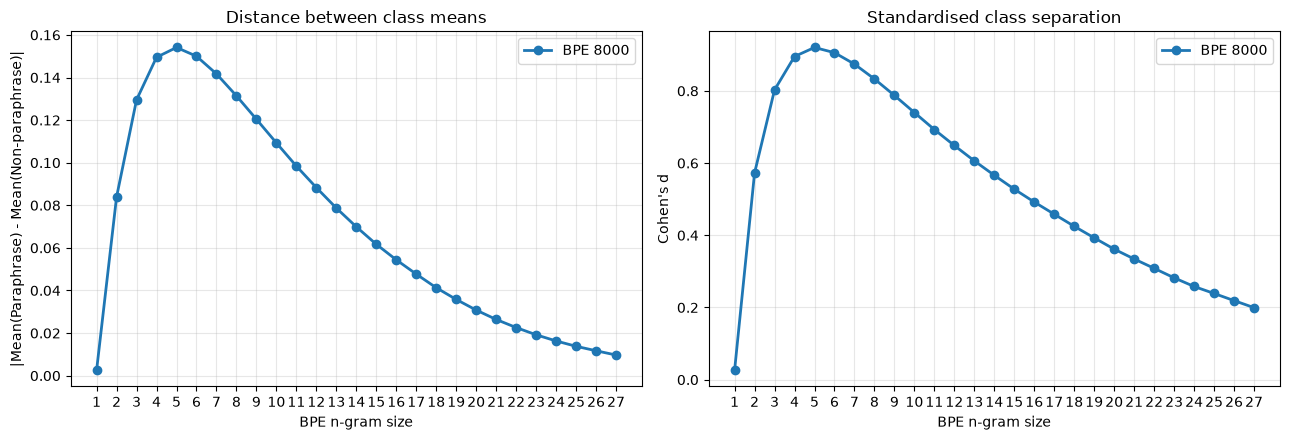

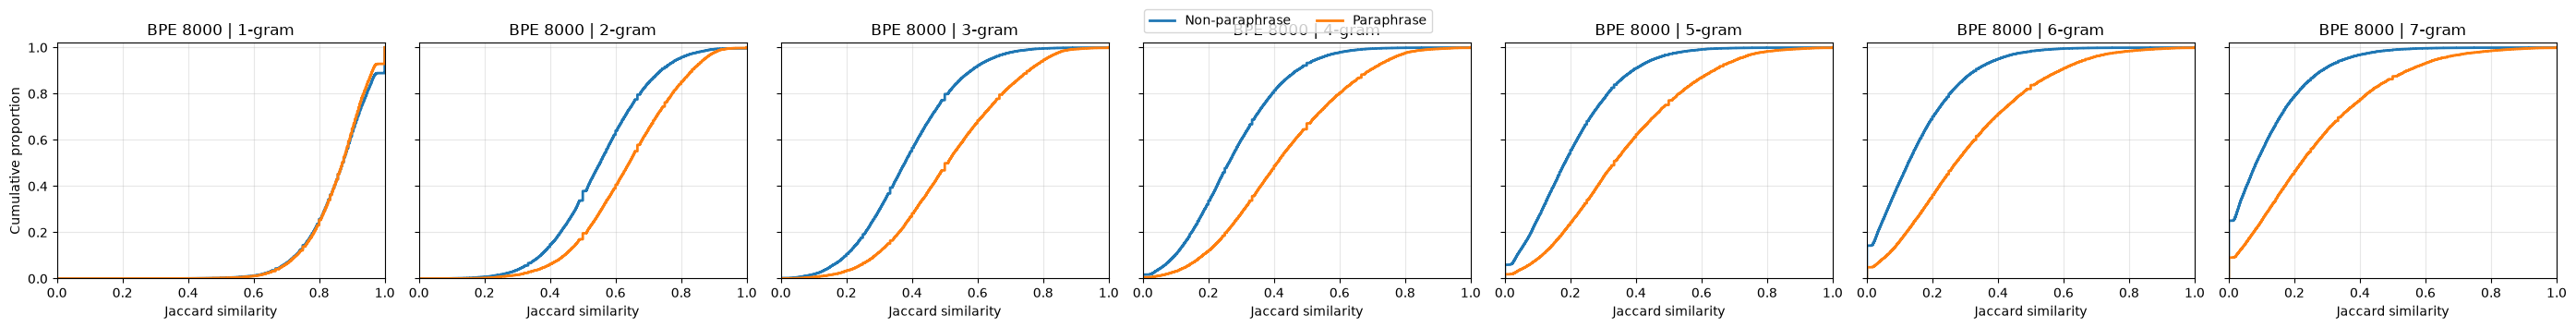

In [ ]:
# ============================================================
# BPE-BASED JACCARD ANALYSIS
# Compare n-gram Jaccard across different BPE vocabulary sizes
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# -------------------- PARAMETERS --------------------

VOCAB_SIZES = [8000]
MIN_FREQ = 2
MAX_N = 27
MAX_PLOT_N = 7

# Use the original training split, as in data_exploration
train_df_bpe = dataset["train"].to_pandas()

labels = train_df_bpe["label"].to_numpy()

# -------------------- HELPER FUNCTIONS --------------------

def bpe_ngram_set(tokens, n):
    """Extract unique consecutive BPE n-grams."""
    return {
        tuple(tokens[i:i+n])
        for i in range(len(tokens) - n + 1)
    }


def bpe_jaccard(a, b):
    """Calculate Jaccard similarity between two sets."""
    union = len(a | b)
    return len(a & b) / union if union else 0.0


def cohens_d(x0, x1):
    """Calculate absolute Cohen's d using pooled standard deviation."""
    n0, n1 = len(x0), len(x1)

    pooled_std = np.sqrt(
        (
            (n0 - 1) * x0.var(ddof=1)
            + (n1 - 1) * x1.var(ddof=1)
        ) / (n0 + n1 - 2)
    )

    return abs(x1.mean() - x0.mean()) / pooled_std if pooled_std > 0 else 0.0


# -------------------- MAIN ANALYSIS --------------------

bpe_results = {}
summary_rows = []

for vocab_size in VOCAB_SIZES:

    print(f"\nAnalyzing BPE vocabulary: {vocab_size}")

    # Retrieve the previously trained tokenizer
    bpe_tokenizer = tokenizers[(vocab_size, MIN_FREQ)]

    # Tokenize both sentences using BPE
    tokens1 = [
        bpe_tokenizer.encode(text).tokens
        for text in train_df_bpe["sentence1"]
    ]

    tokens2 = [
        bpe_tokenizer.encode(text).tokens
        for text in train_df_bpe["sentence2"]
    ]

    results_by_n = {}

    for n in range(1, MAX_N + 1):

        # Generate BPE n-gram sets
        sets1 = [bpe_ngram_set(t, n) for t in tokens1]
        sets2 = [bpe_ngram_set(t, n) for t in tokens2]

        # Calculate Jaccard for every sentence pair
        jac = np.array([
            bpe_jaccard(a, b)
            for a, b in zip(sets1, sets2)
        ])

        # Separate classes
        j0 = jac[labels == 0]
        j1 = jac[labels == 1]

        mean_dist = abs(j1.mean() - j0.mean())

        # Store results
        results_by_n[n] = jac

        summary_rows.append({
            "vocab_size": vocab_size,
            "n": n,
            "mean_non_para": j0.mean(),
            "mean_para": j1.mean(),
            "mean_dist": mean_dist,
            "cohens_d": cohens_d(j0, j1),
            "pct_empty_pairs": 100 * np.mean([
                not (a or b)
                for a, b in zip(sets1, sets2)
            ])
        })

    bpe_results[vocab_size] = results_by_n


# -------------------- RESULTS TABLE --------------------

bpe_summary = pd.DataFrame(summary_rows).round(4)

display(bpe_summary)


# -------------------- OPTIMAL N FOR EACH VOCABULARY --------------------

optimal_rows = []

for vocab_size in VOCAB_SIZES:

    subset = bpe_summary[
        bpe_summary["vocab_size"] == vocab_size
    ]

    best_dist = subset.loc[subset["mean_dist"].idxmax()]
    best_d = subset.loc[subset["cohens_d"].idxmax()]

    optimal_rows.append({
        "vocab_size": vocab_size,
        "best_n_mean_dist": int(best_dist["n"]),
        "best_mean_dist": best_dist["mean_dist"],
        "best_n_cohens_d": int(best_d["n"]),
        "best_cohens_d": best_d["cohens_d"]
    })

optimal_summary = pd.DataFrame(optimal_rows).round(4)

print("\nOptimal n-gram size for each BPE vocabulary:")
display(optimal_summary)


# -------------------- PLOT 1: METRIC COMPARISON --------------------

fig, axes = plt.subplots(
    1, 2,
    figsize=(13, 4.5)
)

for vocab_size in VOCAB_SIZES:

    subset = bpe_summary[
        bpe_summary["vocab_size"] == vocab_size
    ]

    axes[0].plot(
        subset["n"],
        subset["mean_dist"],
        marker="o",
        linewidth=2,
        label=f"BPE {vocab_size}"
    )

    axes[1].plot(
        subset["n"],
        subset["cohens_d"],
        marker="o",
        linewidth=2,
        label=f"BPE {vocab_size}"
    )

axes[0].set_title("Distance between class means")
axes[0].set_xlabel("BPE n-gram size")
axes[0].set_ylabel(
    "|Mean(Paraphrase) - Mean(Non-paraphrase)|"
)

axes[1].set_title("Standardised class separation")
axes[1].set_xlabel("BPE n-gram size")
axes[1].set_ylabel("Cohen's d")

for ax in axes:
    ax.set_xticks(range(1, MAX_N + 1))
    ax.grid(alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.savefig("images/bpe_jaccard_metrics.png", dpi=300, bbox_inches="tight")
plt.show()


# -------------------- PLOT 2: CUMULATIVE DISTRIBUTIONS --------------------

fig, axes = plt.subplots(
    len(VOCAB_SIZES),
    MAX_PLOT_N,
    figsize=(4 * MAX_PLOT_N, 3.5 * len(VOCAB_SIZES)),
    sharex=True,
    sharey=True,
    squeeze=False
)

for row, vocab_size in enumerate(VOCAB_SIZES):

    for col, n in enumerate(range(1, MAX_PLOT_N + 1)):

        ax = axes[row, col]
        jac = bpe_results[vocab_size][n]

        for label, name in [
            (0, "Non-paraphrase"),
            (1, "Paraphrase")
        ]:

            values = np.sort(jac[labels == label])
            cumulative = np.arange(1, len(values) + 1) / len(values)

            # Anchor curves at (0,0) and (1,1)
            values = np.r_[0, values, 1]
            cumulative = np.r_[0, cumulative, 1]

            ax.step(
                values,
                cumulative,
                where="post",
                linewidth=2,
                label=name
            )

        ax.set_title(f"BPE {vocab_size} | {n}-gram")
        ax.set_xlim(0, 1)
        ax.set_ylim(0, 1.02)
        ax.grid(alpha=0.3)

        if col == 0:
            ax.set_ylabel("Cumulative proportion")

        if row == len(VOCAB_SIZES) - 1:
            ax.set_xlabel("Jaccard similarity")

# One shared legend
handles, legend_labels = axes[0, 0].get_legend_handles_labels()

fig.legend(
    handles,
    legend_labels,
    loc="upper center",
    ncol=2,
    bbox_to_anchor=(0.5, 1.02)
)

plt.tight_layout()
plt.savefig(
    "images/bpe_jaccard_cumulative.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


## 4. Representation spaces

An encoder maps one input to a vector. For a pair we encode each sentence with a base encoder and concatenate the two vectors (`PairEncoder`):

| Name | Base encoder (per sentence) |
|---|---|
| `TokenIndicator` | 1 if the token appears in the sentence, else 0 |
| `BagOfWords` | number of times each token appears in the sentence |
| `Frequency Ngram` | number of times each N-group of token appears in the sentence |

In [24]:
from collections import OrderedDict
from src.encoders import TokenIndicator, BagOfWords, PairEncoder, NgramBagOfWords

encoders = {
    "NGram": PairEncoder(NgramBagOfWords(tokenizer, n = 5, include_lower=False).fit(corpus)),
    "TokenIndicator": PairEncoder(TokenIndicator(tokenizer)),
    "BagOfWords":  PairEncoder(BagOfWords(tokenizer)),
}

encoders_concat = {
    "NGram": PairEncoder(NgramBagOfWords(tokenizer, n = 5, include_lower=False).fit(corpus), mode="concat"),
    "TokenIndicator": PairEncoder(TokenIndicator(tokenizer), mode="concat"),
    "BagOfWords":     PairEncoder(BagOfWords(tokenizer), mode="concat"),
}

TypeError: PairEncoder.__init__() got an unexpected keyword argument 'mode'

## 5. Cross-validation setup

Each PAWS example is a **pair** of sentences, so an input `x` is the tuple `(sentence1, sentence2)`. The code from the tutorial works with `(input, label)` pairs, so we build them in that format.

We run 5-fold cross-validation on the **train** split: the data is shuffled and split into 5 parts, and each model is trained 5 times, each time evaluating on a different part. The validation and test splits of PAWS are left untouched. The seed makes the shuffling reproducible, and all models use exactly the same folds so that the comparison is fair.

In [8]:
from src import experiment, clslib, analysis
from src.dataset import paws_pairs

outcome_space = clslib.NamedClasses(["different meaning", "paraphrase"])
results_folder = "results"

my_seeds = [0]
num_folds = 5
my_cross_validation_sets = [
    experiment.cross_validation_split(paws_pairs(dataset["train"]), k=num_folds, seed=seed)
    for seed in my_seeds
]

## 6. Logistic regression (log-linear model)

We train one logistic regression per representation space and per fold, and record the accuracy on the held-out fold.

In [21]:
my_classifiers = OrderedDict()

for enc_name, enc in encoders.items():
    name = f"logistic_{enc_name}"
    if name in my_classifiers:
        continue
    my_classifiers[name] = [
        experiment.cross_validation_experiment(
            data_splits=my_cross_validation_sets[run],
            outcome_space=outcome_space,
            encoder=enc,
            model_option="logistic",
            save_to=f"{results_folder}/{name}/seed-{seed}",
            loglin_args={"max_iter": 100},
        )
        for run, seed in enumerate(my_seeds)
    ]

analysis.plot_box_and_points(analysis.make_data_frame(my_classifiers))

  0%|          | 0/5 [00:00<?, ?it/s]

d:\Documentos\MSc Arttificial Itelligence UvA\Natural Language Processing 1\Assignments\nlp1\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
d:\Documentos\MSc Arttificial Itelligence UvA\Natural Language Processing 1\Assignments\nlp1\.venv\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


KeyboardInterrupt: 

In [10]:
import inspect

# Inspect the actual encoder being used
for name, enc in encoders.items():

    print(f"\nEncoder: {name}")
    print("Base class:", type(enc.base))
    print("Has __len__:", hasattr(type(enc.base), "__len__"))

    print(inspect.getsource(type(enc.base)))


Encoder: NGram
Base class: <class 'src.encoders.NgramBagOfWords'>
Has __len__: True
class NgramBagOfWords:
    """Cuenta cuántas veces aparece cada n-grama de tokens BPE en una frase.

    n             : tamaño del n-grama (1 = BagOfWords normal, 2 = bigramas, ...)
    include_lower : si True usa todos los n-gramas de tamaño 1..n; si False solo tamaño n
    min_count     : descarta n-gramas que aparecen menos de esto en el corpus de ajuste
    max_features  : se queda con los max_features n-gramas más frecuentes
    """

    def __init__(self, tokenizer, n=2, include_lower=False, min_count=5, max_features=8000):
        self.tokenizer = tokenizer
        self.n = n
        self.include_lower = include_lower
        self.min_count = min_count
        self.max_features = max_features
        self.vocab = None  # dict: n-gram (tokens tuple) -> index

    def _ngrams(self, text):
        tokens = self.tokenizer.encode(text).tokens
        sizes = range(1, self.n + 1) if self.include_lowe

## 7. MLP (one hidden layer)

Same experiment, replacing the logistic regression with a neural network with one hidden layer (128 units, ReLU, dropout 0.1).

  0%|          | 0/5 [00:00<?, ?it/s]

Transforming documents...
Document transformation done! Time taken: 17.718 seconds
Dataloader done! Time taken: 0.006 seconds
Training...


  0%|          | 0/3 [00:00<?, ?it/s]

d:\Documentos\MSc Arttificial Itelligence UvA\Natural Language Processing 1\Assignments\nlp1\src\smlp.py:69: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\torch\csrc\utils\tensor_new.cpp:252.)
  indices = torch.tensor([x.row, x.col], dtype=torch.long)
d:\Documentos\MSc Arttificial Itelligence UvA\Natural Language Processing 1\Assignments\nlp1\src\smlp.py:72: UserWarning: Sparse invariant checks are implicitly disabled. Memory errors (e.g. SEGFAULT) will occur when operating on a sparse tensor which violates the invariants, but checks incur performance overhead. To silence this warning, explicitly opt in or out. See `torch.sparse.check_sparse_tensor_invariants.__doc__` for guidance.  (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\aten\src\ATen\Context.cpp:923.)


Epoch 01 | train loss: 0.6854 | train acc: 0.5644 | val loss: 0.6841 | val acc: 0.5708
Epoch 02 | train loss: 0.6761 | train acc: 0.5816 | val loss: 0.6807 | val acc: 0.5826
Epoch 03 | train loss: 0.6665 | train acc: 0.5893 | val loss: 0.6809 | val acc: 0.5773
Training done! Time taken: 49.272 seconds
Transforming documents...
Document transformation done! Time taken: 17.853 seconds
Dataloader done! Time taken: 0.007 seconds
Training...


  0%|          | 0/3 [00:00<?, ?it/s]

... (27 outputs left out)

  0%|          | 0/3 [00:00<?, ?it/s]

Epoch 01 | train loss: 0.6843 | train acc: 0.5750 | val loss: 0.6853 | val acc: 0.5849
Epoch 02 | train loss: 0.6651 | train acc: 0.6103 | val loss: 0.6921 | val acc: 0.5623
Epoch 03 | train loss: 0.6473 | train acc: 0.6235 | val loss: 0.7056 | val acc: 0.5513
Training done! Time taken: 55.550 seconds
Transforming documents...
Document transformation done! Time taken: 19.906 seconds
Dataloader done! Time taken: 0.007 seconds
Training...


  0%|          | 0/3 [00:00<?, ?it/s]

Epoch 01 | train loss: 0.6854 | train acc: 0.5710 | val loss: 0.6804 | val acc: 0.5986
Epoch 02 | train loss: 0.6675 | train acc: 0.6051 | val loss: 0.6836 | val acc: 0.5887
Epoch 03 | train loss: 0.6490 | train acc: 0.6195 | val loss: 0.6944 | val acc: 0.5473
Training done! Time taken: 55.134 seconds


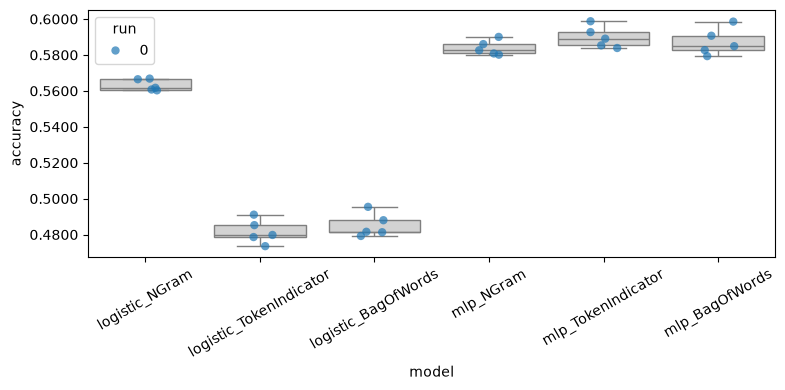

In [11]:
mlp_args = {"hidden_dim": 128, "dropout": 0.1, "batch_size": 64,
            "learning_rate": 1e-4, "weight_decay": 1e-4, "num_epochs": 3}

for enc_name, enc in encoders.items():
    name = f"mlp_{enc_name}"
    if name in my_classifiers:
        continue
    my_classifiers[name] = [
        experiment.cross_validation_experiment(
            data_splits=my_cross_validation_sets[run],
            outcome_space=outcome_space,
            encoder=enc,
            model_option="mlp",
            save_to=f"{results_folder}/{name}/seed-{seed}",
            smlp_args=mlp_args,
        )
        for run, seed in enumerate(my_seeds)
    ]

analysis.plot_box_and_points(analysis.make_data_frame(my_classifiers))

## 9. Evaluation analysis



,A,B,mean_diff,HDI95_low,HDI95_high,P(A better),P(ROPE),P(B better),decision
0,logistic_BagOfWords,logistic_NGram,-0.078,-0.086,-0.070,0.000,0.000,1.000,logistic_NGram better
1,logistic_BagOfWords,logistic_TokenIndicator,0.003,0.000,0.006,0.002,0.998,0.000,equivalent
2,logistic_BagOfWords,mlp_BagOfWords,-0.102,-0.113,-0.092,0.000,0.000,1.000,mlp_BagOfWords better
3,logistic_BagOfWords,mlp_NGram,-0.099,-0.108,-0.090,0.000,0.000,1.000,mlp_NGram better
4,logistic_BagOfWords,mlp_TokenIndicator,-0.105,-0.115,-0.094,0.000,0.000,1.000,mlp_TokenIndicator better
5,logistic_NGram,logistic_TokenIndicator,0.082,0.073,0.090,1.000,0.000,0.000,logistic_NGram better
6,logistic_NGram,mlp_BagOfWords,-0.024,-0.033,-0.015,0.000,0.007,0.993,mlp_BagOfWords better
7,logistic_NGram,mlp_NGram,-0.021,-0.023,-0.018,0.000,0.000,1.000,mlp_NGram better
8,logistic_NGram,mlp_TokenIndicator,-0.027,-0.033,-0.021,0.000,0.001,0.999,mlp_TokenIndicator better
9,logistic_TokenIndicator,mlp_BagOfWords,-0.106,-0.115,-0.096,0.000,0.000,1.000,mlp_BagOfWords better


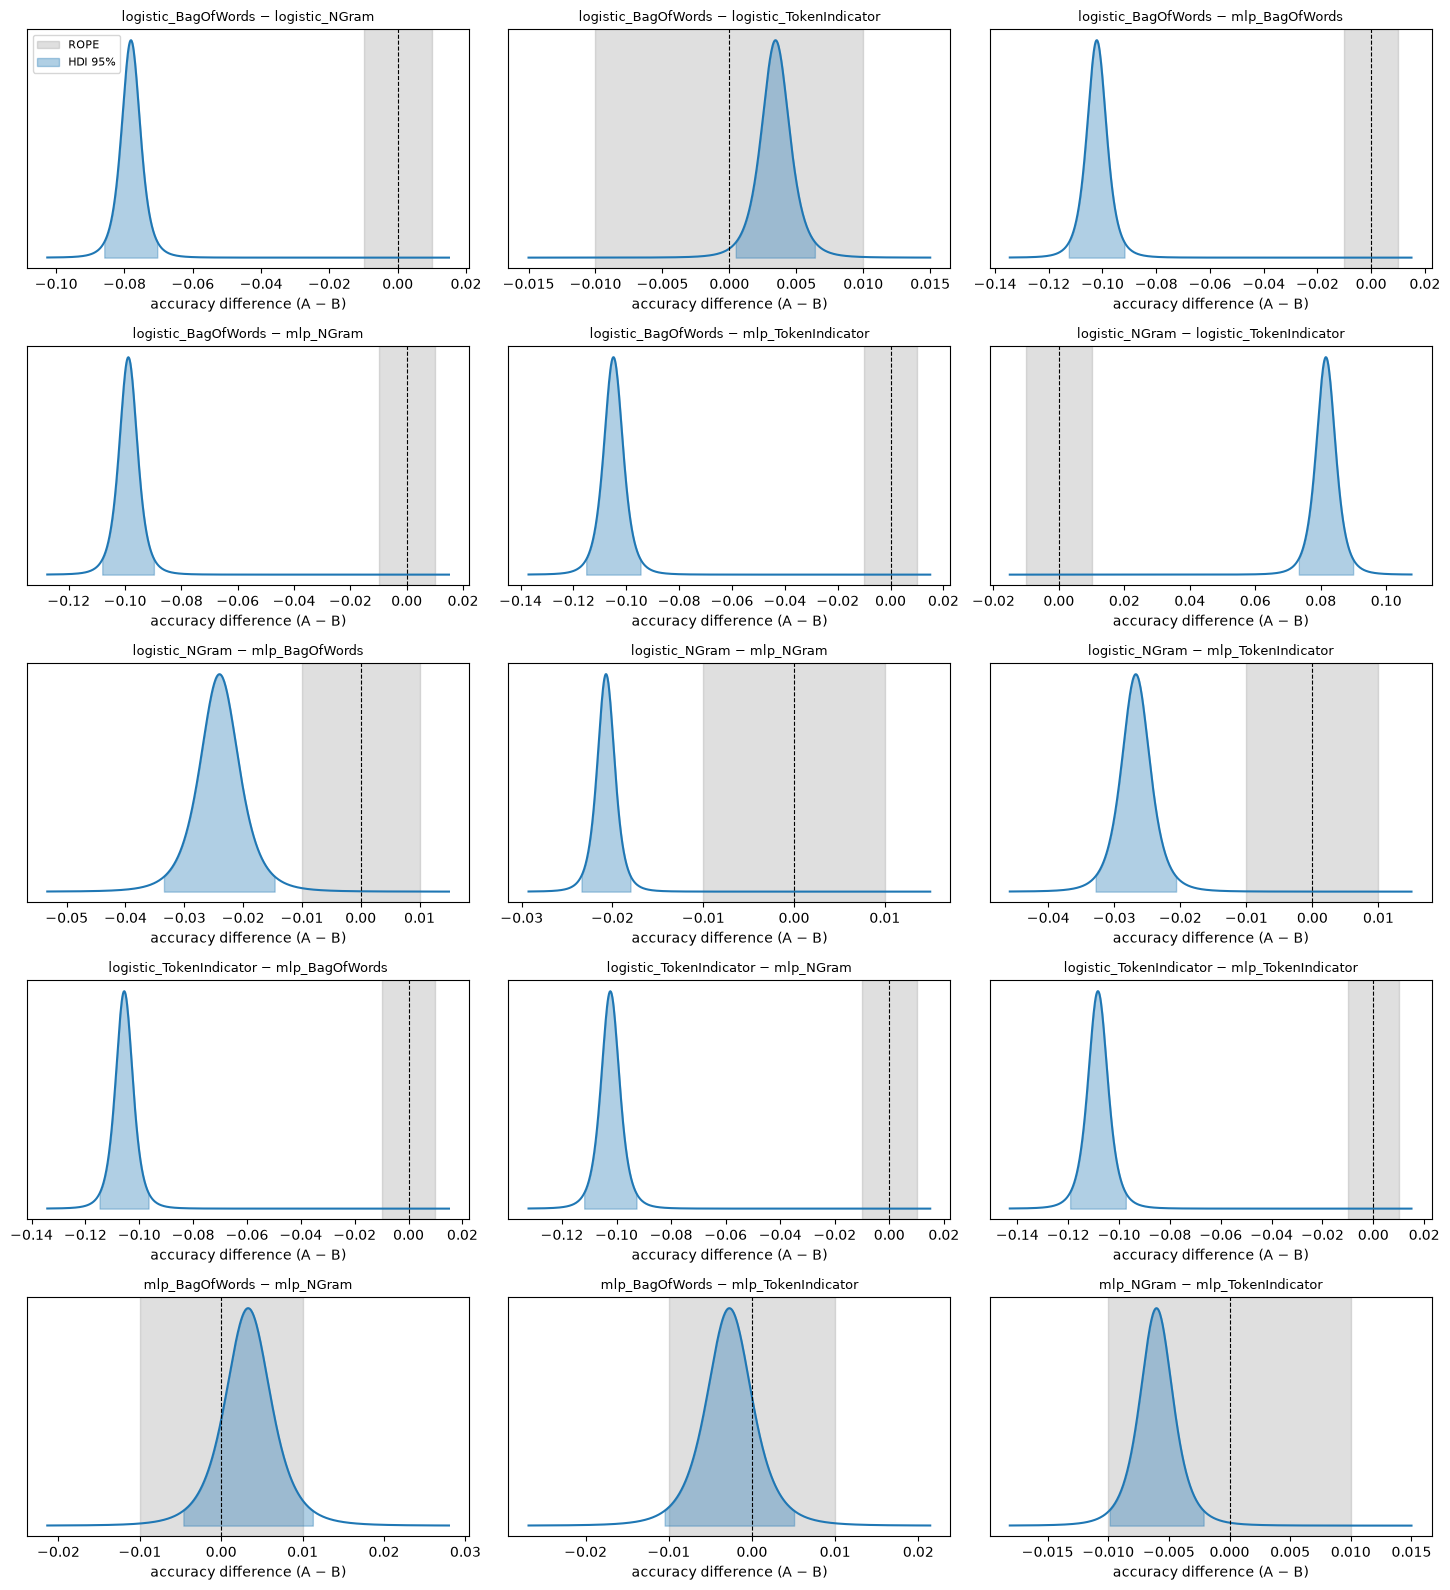

In [12]:
from src.bayes_rope import scores_by_model, compare_models, plot_posteriors

df   = analysis.make_data_frame(my_classifiers)   # columnas: model, accuracy, run
wide = scores_by_model(df)                      # una fila por fold, una columna por modelo

ROPE = 0.01                                       # 1 punto de accuracy
tabla, posts = compare_models(wide, k=num_folds, rope=ROPE)
display(tabla.round(3))
plot_posteriors(posts, ROPE);

In [20]:
from sklearn.metrics import confusion_matrix, classification_report, f1_score
import numpy as np

# Concatenate predictions from all 5 folds
y_pred = np.concatenate(list(predictions.values()))

# Obtain the gold labels in the same fold order
y_true = np.concatenate([
    fold["labels"] for fold in my_cross_validation_sets[0]
])

print("Confusion Matrix:")
print(confusion_matrix(y_true, y_pred))

print("\nClassification Report:")
print(classification_report(y_true, y_pred))

print("Macro F1:", f1_score(y_true, y_pred, average="macro"))

TypeError: 'int' object is not subscriptable